# Perceptron

A **Perceptron** is one of the simplest neural network models. It is used for **binary classification**, meaning it classifies inputs into one of two classes (0 or 1).

## How Does a Perceptron Work?

Suppose we have an input vector:

$$
x = [x_1, x_2, \ldots, x_n]
$$ 

Each input feature has a corresponding weight:

$$
w = [w_1, w_2, \ldots, w_n]
$$

The perceptron first calculates a weighted sum:

$$
z = w^T x + b = \sum_{i=1}^{n} w_i x_i + b
$$

Then, it applies a **step activation function** to produce the prediction:

$$
\hat{y} =
\begin{cases}
1 & \text{if } z \geq 0\\
0 & \text{if } z < 0
\end{cases}
$$

Where:

- $x$: Input features
- $w$: Weights
- $b$: Bias
- $z$: Weighted sum
- $\hat{y}$: Predicted class

## How Do We Update the Weights?

The main idea is:

**If the perceptron makes an incorrect prediction, we adjust its weights to make the correct prediction more likely.**

The perceptron learning rule is:

$$
{w_{\text{new}} = w_{\text{old}} + \eta(y-\hat{y})x}
$$

The bias is updated using:

$$
{b_{\text{new}} = b_{\text{old}} + \eta(y-\hat{y})}
$$

Where:

- $\eta$: Learning rate
- $y$: Actual label
- $\hat{y}$: Predicted label
- $x$: Input vector


## Training Process

The perceptron repeatedly performs the following steps:

1. Take a training example.
2. Calculate the weighted sum and prediction.
3. Compare the prediction with the actual label.
4. Update the weights and bias if the prediction is incorrect.
5. Move to the next training example.

This process is repeated over the training dataset for multiple **epochs**.

![perceptron](/image/Perceptron.jpg)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_classification

## Generate Linearly Separable Data

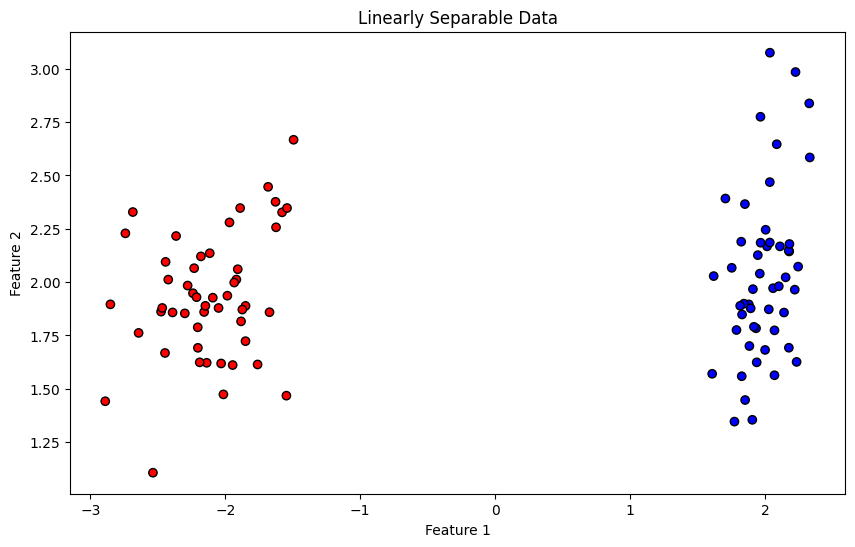

In [2]:
X, y = make_classification(
    n_samples=100,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    flip_y=0,
    class_sep=2.0,
    random_state=1
)

plt.figure(figsize=(10, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', edgecolors='k')
plt.title("Linearly Separable Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

## Perceptron Classifier from scratch

In [3]:
class SimplePerceptron:
    def __init__(self, learning_rate=0.1, n_iters=1000):
        self.lr = learning_rate
        self.n_iters = n_iters
        self.weights = None
        self.bias = None
        self.error = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0

        for iter in range(self.n_iters):
            error = 0
            for idx in range(n_samples):
                linear_output = np.dot(X[idx], self.weights) + self.bias
                y_predicted = np.where(linear_output >= 0, 1, 0)

                update = self.lr * (y[idx] - y_predicted)
                self.weights += update * X[idx]
                self.bias += update
                if y[idx] != y_predicted:
                    # misclassified
                    error += 1
            self.error.append(error)
            
    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return np.where(linear_output >= 0, 1, 0)

## Train the Perceptron

In [4]:
perceptron = SimplePerceptron(learning_rate=0.1, n_iters=10)
perceptron.fit(X, y)
predictions = perceptron.predict(X)

print(f"Final Weights: {perceptron.weights}")
print(f"Final Bias: {perceptron.bias}")

Final Weights: [-0.40582332  0.0225111 ]
Final Bias: 0.0


## Visualize Decision Regions

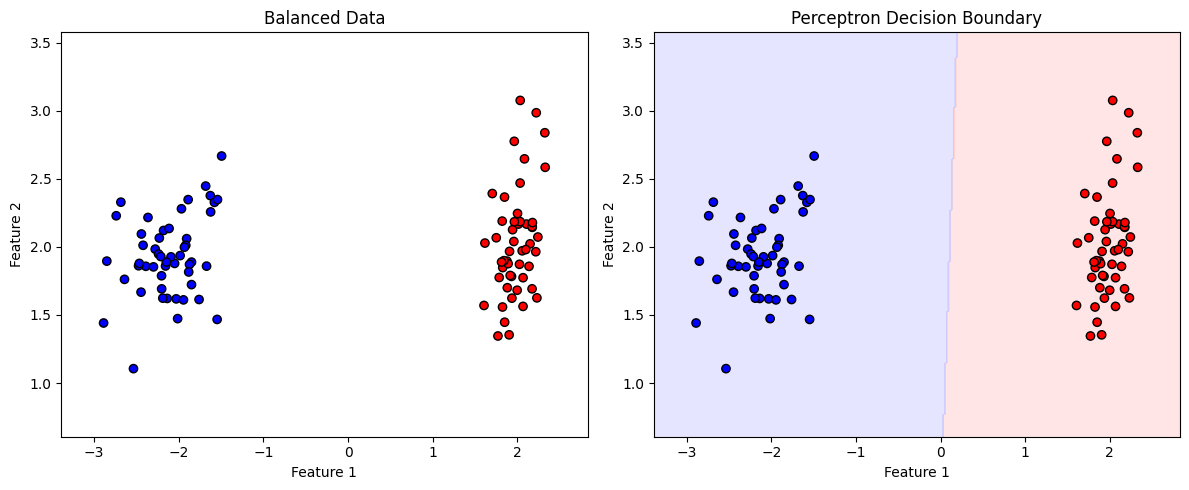

In [5]:
def plot_decision_boundary(ax, X, y, model=None, title=""):
    x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
    y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))

    if model is not None:
        # Predict class label for each point on the grid
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        # Show regions based on prediction
        ax.contourf(xx, yy, Z, cmap=ListedColormap(['#FFCCCC', '#CCCCFF']), alpha=0.5)

    # Plot training data
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap=ListedColormap(['red', 'blue']), edgecolor='k')
    ax.set_title(title)
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

fig, axs = plt.subplots(1, 2, figsize=(12, 5))    

plot_decision_boundary(axs[0], X, y, None, "Balanced Data")
plot_decision_boundary(axs[1], X, y, perceptron, "Perceptron Decision Boundary")
plt.tight_layout()
plt.show()

## Convergence

An important property of the perceptron learning algorithm is:

**The perceptron converges if the training data is linearly separable.**

This means that there exists a linear decision boundary that can correctly separate the two classes.

If the data is not linearly separable, the algorithm may never find weights that correctly classify all training examples.

## Perceptron with Labels {-1, +1}

Another common way to represent binary classification labels is using -1 and +1 instead of 0 and 1.

In this representation:

- Class 0 becomes -1.
- Class 1 becomes +1.

This changes the prediction function and the weight update rule.

### Prediction

Instead of using the previous step activation function, we use the sign function:

$$
\hat{y}^{(i)} = \operatorname{sign}(w^T x^{(i)} + b)
$$

Where:

$$
\operatorname{sign}(z) =
\begin{cases}
+1 & \text{if } z \geq 0 \\
-1 & \text{if } z < 0
\end{cases}
$$

### Weight Update Rule

The perceptron updates its weights only when a sample is misclassified.

For a misclassified sample, the update rule becomes:

$$
w_{\text{new}} = w_{\text{old}} + \eta y^{(i)} x^{(i)}
$$

The bias is updated as:

$$
b_{\text{new}} = b_{\text{old}} + \eta y^{(i)}
$$

Where:
- $\eta$: Learning rate
- $y^{(i)}$: Actual label (-1 or +1)
- $x^{(i)}$: Input feature vector

### Loss Function

We use the following loss function to measure the number of misclassified samples:

$$
J(\mathbf{w},b) =
\sum_{i=1}^{n}
\left(
\frac{y^{(i)}-\operatorname{sign}(\hat{y}^{(i)})}{2}
\right)^2
$$

Where:

$$
\hat{y}^{(i)} = \mathbf{w}^T\mathbf{x}^{(i)}+b
$$

This loss function works because both the actual and predicted labels belong to {-1, +1}.

For each sample, there are two possible cases:

1. Correct prediction

If the predicted label equals the actual label:

$$
y^{(i)} = \operatorname{sign}(\hat{y}^{(i)})
$$

Then:

$$
J_i = \left(\frac{0}{2}\right)^2 = 0
$$

2. Incorrect prediction

If the predicted label differs from the actual label:

$$
y^{(i)} \neq \operatorname{sign}(\hat{y}^{(i)})
$$

Their difference is either +2 or -2. Therefore:

$$
J_i = \left(\frac{\pm 2}{2}\right)^2 = 1
$$

Thus, the total loss is simply the number of misclassified samples.

### New SimplePerceptron implementation

In [6]:
class SimplePerceptron2:
    def __init__(self, learning_rate=0.1, n_iters=1000):
        self.lr = learning_rate
        self.n_iters = n_iters
        self.weights = None
        self.bias = None
        self.loss = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0

        for epoch in range(self.n_iters):
            for idx in range(n_samples):
                linear_output = np.dot(X[idx], self.weights) + self.bias
                y_predicted = np.where(linear_output >= 0, 1, -1)

                if y[idx] != y_predicted:
                    self.weights += self.lr * y[idx] * X[idx]
                    self.bias += self.lr * y[idx]

            self.loss.append(self.calculate_loss(X, y))

    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return np.where(linear_output >= 0, 1, -1)

    def calculate_loss(self, X, y):
        # number of misclassified samples
        predictions = self.predict(X)
        return np.sum(((y - predictions) / 2) ** 2)

## Imbalanced Data

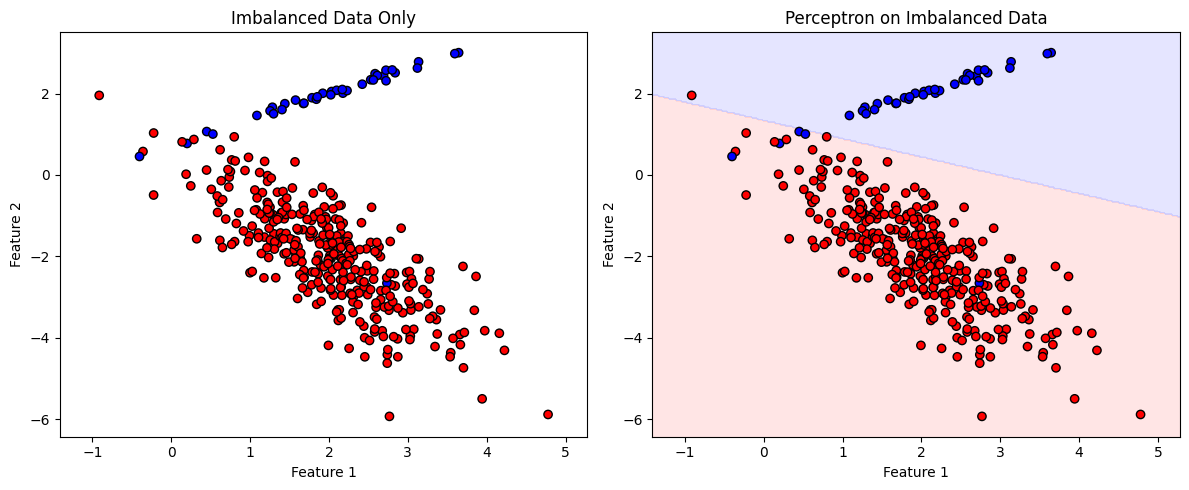

In [7]:
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split

# Generate a synthetic 2D binary classification dataset with class imbalance (90% vs 10%)
X, y = make_classification(
    n_classes=2,            # Binary classification
    class_sep=2,            # Distance between classes (for separability)
    weights=[0.9, 0.1],     # Class imbalance (90% class 0, 10% class 1)
    n_informative=2,        # Number of informative features
    n_redundant=0,          # No redundant features
    n_features=2,           # Only 2 features for easy visualization
    n_clusters_per_class=1,
    n_samples=500,
    random_state=42
)

# Split into training and test sets, maintaining class ratio (stratify)
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

# Initialize and train a Perceptron on imbalanced data
clf = Perceptron()
clf.fit(X_train, y_train)

# Plot the raw imbalanced data and the decision boundary learned by Perceptron
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Left: original data only
plot_decision_boundary(axs[0], X_train, y_train, model=None, title="Imbalanced Data Only")

# Right: decision boundary learned on imbalanced data
plot_decision_boundary(axs[1], X_train, y_train, model=clf, title="Perceptron on Imbalanced Data")

plt.tight_layout()
plt.show()

# Real-World Example: Breast Cancer

In this part, we will use [breast cancer dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html) of scikit-learn which is a classic binary classification dataset used for machine learning. This dataset contains multiple features for tumors as well as it's label (either benign or malignant).

In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Load breast cancer dataset 
data = load_breast_cancer()
X = data.data
y = data.target  # Labels: 0 = malignant, 1 = benign

print(data.feature_names)

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


- We focus our analysis on two specific features — **mean perimeter** and **mean smoothnes** — to make the classification problem visually interpretable. 
- Standardize these two features to ensure consistent scaling
- Add a bias term manually
- Divide the dataset into training and validation sets with an 80/20 ratio. 

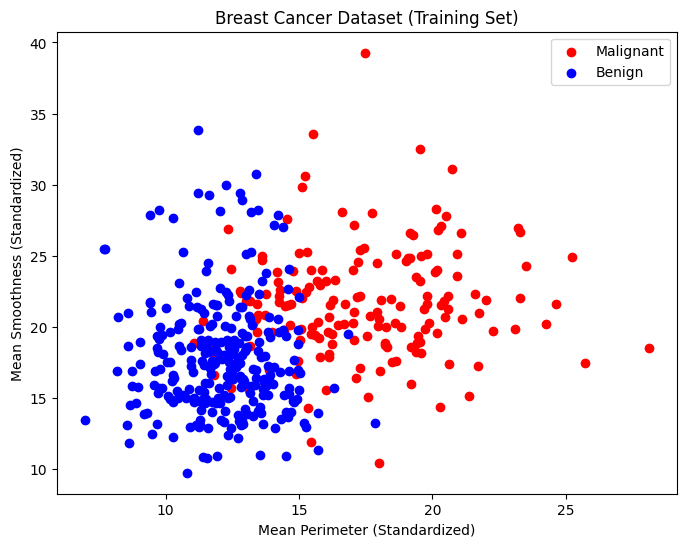

In [9]:
# Convert to pandas DataFrame for easy handling
df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y

# Select two features for visualization and classification
selected_features = ['mean radius', 'mean texture']
X = df[selected_features].values

# Standardize features
# scaler = StandardScaler()
# X = scaler.fit_transform(X)

# Split data into training and validation sets (80/20)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Plot training data
plt.figure(figsize=(8, 6))
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
            color='red', label='Malignant')
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
            color='blue', label='Benign')
plt.xlabel('Mean Perimeter (Standardized)')
plt.ylabel('Mean Smoothness (Standardized)')
plt.title('Breast Cancer Dataset (Training Set)')
plt.legend()
plt.show()

Train Perceptron on the Training Set:

In [10]:
# Initialize and train a custom Perceptron (your own implementation)
percept = SimplePerceptron(learning_rate=0.01, n_iters=1000)
percept.fit(X_train, y_train)

# Display final learned weights and bias
print(f"Final Weights: {percept.weights}")
print(f"Final Bias: {percept.bias}")

Final Weights: [-1.63173 -0.3517 ]
Final Bias: 30.740000000002006


As you remember, samples are not linearly separable. We can expect number of misclassifications not to converge to 0:

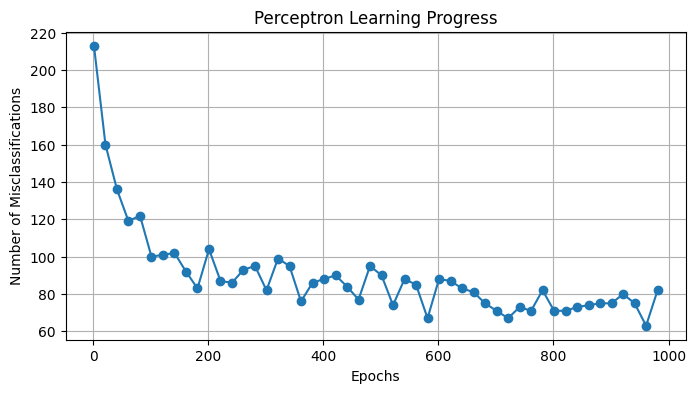

In [11]:
# Plot number of misclassified samples every 20 epochs
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(percept.error) + 1, 20), percept.error[::20], marker='o')
plt.xlabel('Epochs')
plt.ylabel('Number of Misclassifications')
plt.title('Perceptron Learning Progress')
plt.grid(True)
plt.show()

Plot Perceptron Decision Boundary on Test Set:

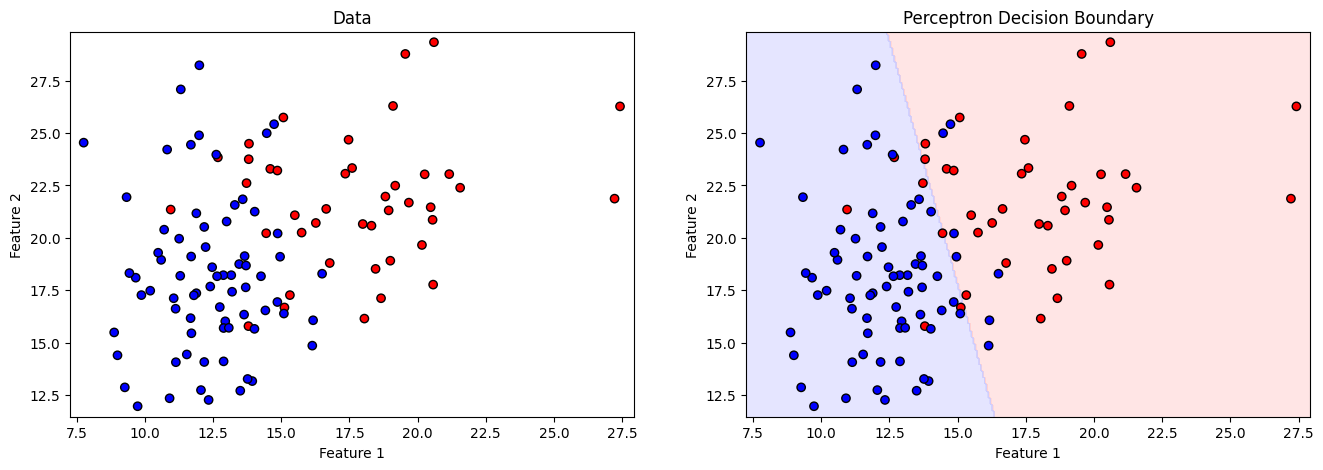

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

plot_decision_boundary(ax[0], X_val, y_val, None, "Data")
plot_decision_boundary(ax[1], X_val, y_val, percept, "Perceptron Decision Boundary")

plt.show()